Nama : Fidya Raihana Salsabila

NIM :  2338015015

In [ ]:
%pip install wget

from pathlib import Path
import os

os.environ["KERAS_HOME"] = str(Path.cwd() / ".tools" / "keras")

import zipfile
import wget
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow:", tf.__version__)
print("GPU:", gpus if gpus else "Tidak terdeteksi; pelatihan menggunakan CPU.")

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

zip_path = data_dir / "UCMerced_LandUse.zip"

if not zip_path.exists():
    wget.download(url, out=str(zip_path))

with zipfile.ZipFile(zip_path) as arsip:
    for nama in arsip.namelist():
        tujuan = (data_dir / nama).resolve()
        if not tujuan.is_relative_to(data_dir.resolve()):
            raise ValueError("Lokasi file ZIP tidak valid")
    arsip.extractall(data_dir)

image_dir = data_dir / "dataset" / "Images"

print("Folder gambar:", image_dir)

Folder gambar: data/dataset/Images


In [ ]:
nama_kelas = sorted(
    folder.name for folder in image_dir.iterdir()
    if folder.is_dir()
)

gambar, label = [], []

for kelas, nama in enumerate(nama_kelas):
    for path in sorted((image_dir / nama).glob("*.tif")):
        with Image.open(path) as img:
            img = img.convert("RGB").resize(
                IMG_SIZE,
                Image.Resampling.BILINEAR
            )
            gambar.append(np.asarray(img))
        label.append(kelas)

X = np.asarray(gambar, dtype="uint8")
y = np.asarray(label, dtype="int32")

del gambar

assert len(nama_kelas) == 21 and len(X) == 2100, \
    "Periksa kelengkapan dataset"

assert np.all(np.bincount(y) == 100), \
    "Setiap kelas seharusnya memiliki 100 gambar"

print("Bentuk data:", X.shape)
print("Kelas:", nama_kelas)

Bentuk data: (2100, 224, 224, 3)
Kelas: ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


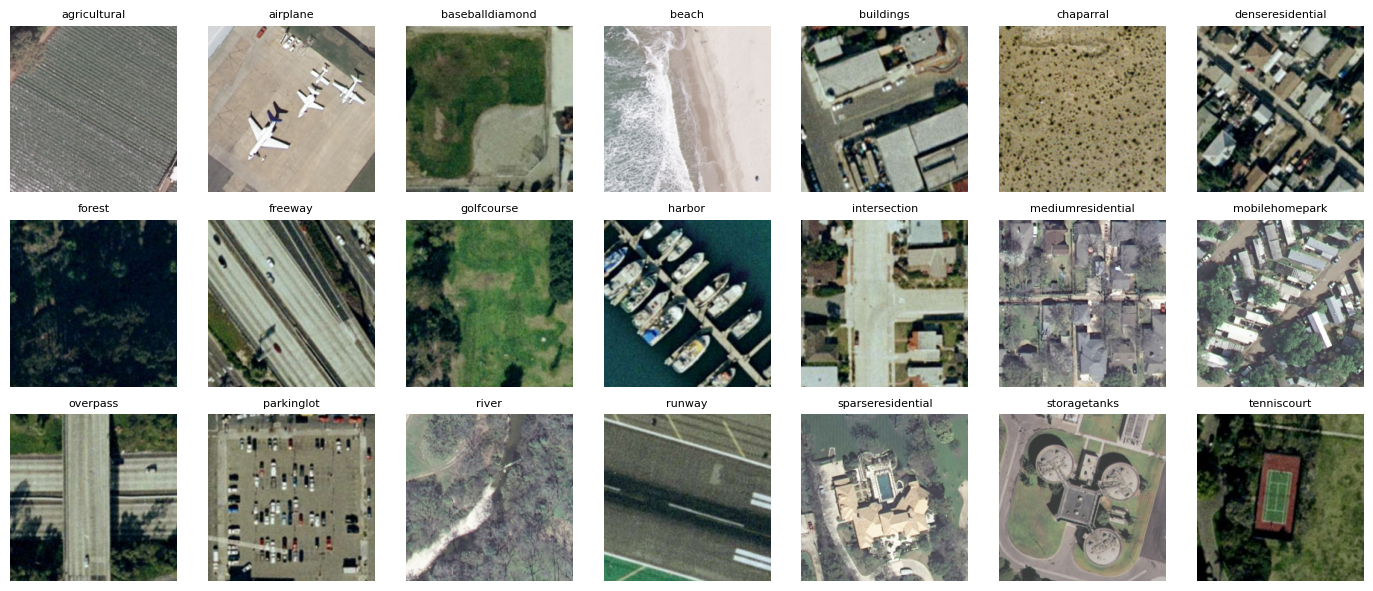

In [ ]:
fig, axes = plt.subplots(3, 7, figsize=(14, 6))

for kelas, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y == kelas)[0]
    ax.imshow(X[idx])
    ax.set_title(nama_kelas[kelas], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
x_train, x_sisa, y_train, y_sisa = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

x_val, x_test, y_val, y_test = train_test_split(
    x_sisa,
    y_sisa,
    test_size=0.50,
    stratify=y_sisa,
    random_state=42
)

print(
    "Train:",
    len(y_train),
    "Validation:",
    len(y_val),
    "Test:",
    len(y_test)
)

Train: 1470 Validation: 315 Test: 315


##Fungsi plot kurva dan evaluasi yang aka digunakan untuk model VGG16 dan MobileNetV2.

In [ ]:
import pandas as pd

hasil = {}

AUGMENTASI = lambda: tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])


def plot_history(h1, h2):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for ax, metric in zip(axes, ["loss", "accuracy"]):
        train = h1.history[metric] + h2.history[metric]
        val = h1.history["val_" + metric] + h2.history["val_" + metric]
        epochs = range(1, len(train) + 1)

        ax.plot(epochs, train, label="Train")
        ax.plot(epochs, val, label="Validation")
        ax.axvline(len(h1.history[metric]), color="gray", linestyle="--")
        ax.set(xlabel="Epoch", ylabel=metric, title=metric)
        ax.legend()

    plt.tight_layout()
    plt.show()


def evaluasi(model, nama):
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    probabilitas = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)
    y_pred = probabilitas.argmax(axis=1)

    print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.2%}")
    print(classification_report(
        y_test, y_pred,
        target_names=nama_kelas,
        zero_division=0
    ))

    fig, ax = plt.subplots(figsize=(14, 12))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=nama_kelas,
        cmap="Blues",
        xticks_rotation=90,
        colorbar=False,
        ax=ax
    )
    ax.set_title(f"{nama} pretrained - UC Merced Land Use")
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(2, 4, figsize=(13, 6))
    for i, ax in enumerate(axes.flat):
        ax.imshow(x_test[i])
        ax.set_title(
            f"Asli: {nama_kelas[y_test[i]]}\n"
            f"Pred: {nama_kelas[y_pred[i]]}\n"
            f"({probabilitas[i].max():.0%})",
            fontsize=9,
            color="green" if y_test[i] == y_pred[i] else "red"
        )
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    hasil[nama] = {"Test loss": test_loss, "Test accuracy": test_acc}


## Model 1: VGG16

In [ ]:
tf.keras.utils.set_random_seed(42)

base_vgg = tf.keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)
base_vgg.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))

x = AUGMENTASI()(inputs)
x = tf.keras.applications.vgg16.preprocess_input(x)
x = base_vgg(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(len(nama_kelas), activation="softmax")(x)

model_vgg = tf.keras.Model(inputs, outputs, name="vgg16_ucmerced")

model_vgg.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_vgg.summary()


Model: "vgg16_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 21)        │     10,773 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,725,461 (56.17 MB)

 Trainable params: 10,773 (42.08 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history_vgg = model_vgg.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch tahap 1:", len(history_vgg.history["loss"]))


Epoch 1/10
92/92 - 15s - 163ms/step - accuracy: 0.2184 - loss: 5.2468 - val_accuracy: 0.5524 - val_loss: 1.7340
Epoch 2/10
92/92 - 8s - 91ms/step - accuracy: 0.5327 - loss: 2.1187 - val_accuracy: 0.7683 - val_loss: 0.8298
Epoch 3/10
92/92 - 9s - 96ms/step - accuracy: 0.6612 - loss: 1.3617 - val_accuracy: 0.8254 - val_loss: 0.5985
Epoch 4/10
92/92 - 9s - 99ms/step - accuracy: 0.7503 - loss: 0.9054 - val_accuracy: 0.8413 - val_loss: 0.4639
Epoch 5/10
92/92 - 9s - 100ms/step - accuracy: 0.7925 - loss: 0.7559 - val_accuracy: 0.8730 - val_loss: 0.3943
Epoch 6/10
92/92 - 9s - 100ms/step - accuracy: 0.8116 - loss: 0.6763 - val_accuracy: 0.9016 - val_loss: 0.3580
Epoch 7/10
92/92 - 9s - 99ms/step - accuracy: 0.8476 - loss: 0.5419 - val_accuracy: 0.8921 - val_loss: 0.3475
Epoch 8/10
92/92 - 9s - 96ms/step - accuracy: 0.8537 - loss: 0.5218 - val_accuracy: 0.9143 - val_loss: 0.2981
Epoch 9/10
92/92 - 9s - 94ms/step - accuracy: 0.8735 - loss: 0.4256 - val_accuracy: 0.9175 - val_loss: 0.2772
Epoch 

In [ ]:
base_vgg.trainable = True
for layer in base_vgg.layers:
    layer.trainable = layer.name.startswith(("block4", "block5"))

model_vgg.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop_ft = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)

history_vgg_ft = model_vgg.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop_ft],
    verbose=2
)

print("Epoch tahap 2:", len(history_vgg_ft.history["loss"]))


Epoch 1/20
92/92 - 19s - 209ms/step - accuracy: 0.8796 - loss: 0.3974 - val_accuracy: 0.9270 - val_loss: 0.2638
Epoch 2/20
92/92 - 13s - 146ms/step - accuracy: 0.9061 - loss: 0.2848 - val_accuracy: 0.9460 - val_loss: 0.1947
Epoch 3/20
92/92 - 14s - 147ms/step - accuracy: 0.9306 - loss: 0.2316 - val_accuracy: 0.9524 - val_loss: 0.1442
Epoch 4/20
92/92 - 13s - 144ms/step - accuracy: 0.9551 - loss: 0.1517 - val_accuracy: 0.9556 - val_loss: 0.1794
Epoch 5/20
92/92 - 13s - 142ms/step - accuracy: 0.9503 - loss: 0.1437 - val_accuracy: 0.9524 - val_loss: 0.1812
Epoch 6/20
92/92 - 13s - 142ms/step - accuracy: 0.9605 - loss: 0.1226 - val_accuracy: 0.9619 - val_loss: 0.1493
Epoch 7/20
92/92 - 13s - 144ms/step - accuracy: 0.9578 - loss: 0.1224 - val_accuracy: 0.9619 - val_loss: 0.1129
Epoch 8/20
92/92 - 13s - 144ms/step - accuracy: 0.9667 - loss: 0.0916 - val_accuracy: 0.9619 - val_loss: 0.1140
Epoch 9/20
92/92 - 13s - 144ms/step - accuracy: 0.9755 - loss: 0.0884 - val_accuracy: 0.9651 - val_loss:

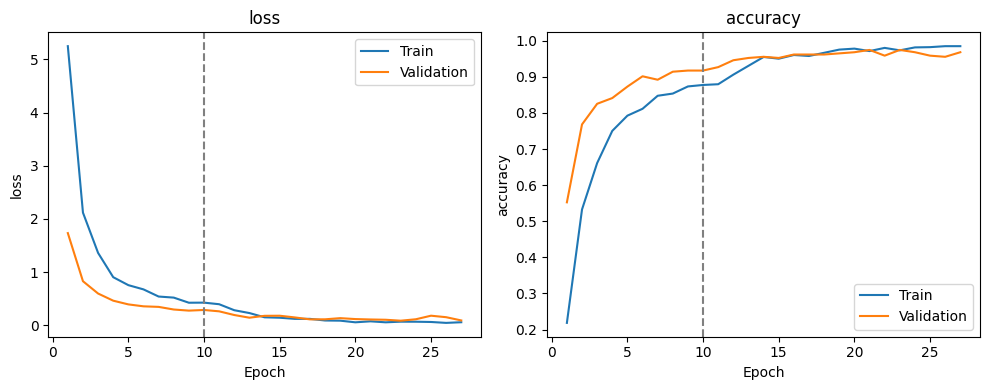

In [ ]:
plot_history(history_vgg, history_vgg_ft)

Test loss: 0.1367 | Test accuracy: 97.14%
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        15
         airplane       1.00      1.00      1.00        15
  baseballdiamond       1.00      1.00      1.00        15
            beach       1.00      1.00      1.00        15
        buildings       1.00      0.87      0.93        15
        chaparral       1.00      1.00      1.00        15
 denseresidential       0.83      1.00      0.91        15
           forest       0.94      1.00      0.97        15
          freeway       1.00      0.93      0.97        15
       golfcourse       1.00      0.87      0.93        15
           harbor       1.00      1.00      1.00        15
     intersection       1.00      0.93      0.97        15
mediumresidential       0.88      1.00      0.94        15
   mobilehomepark       1.00      0.93      0.97        15
         overpass       0.94      1.00      0.97        15
       parkin

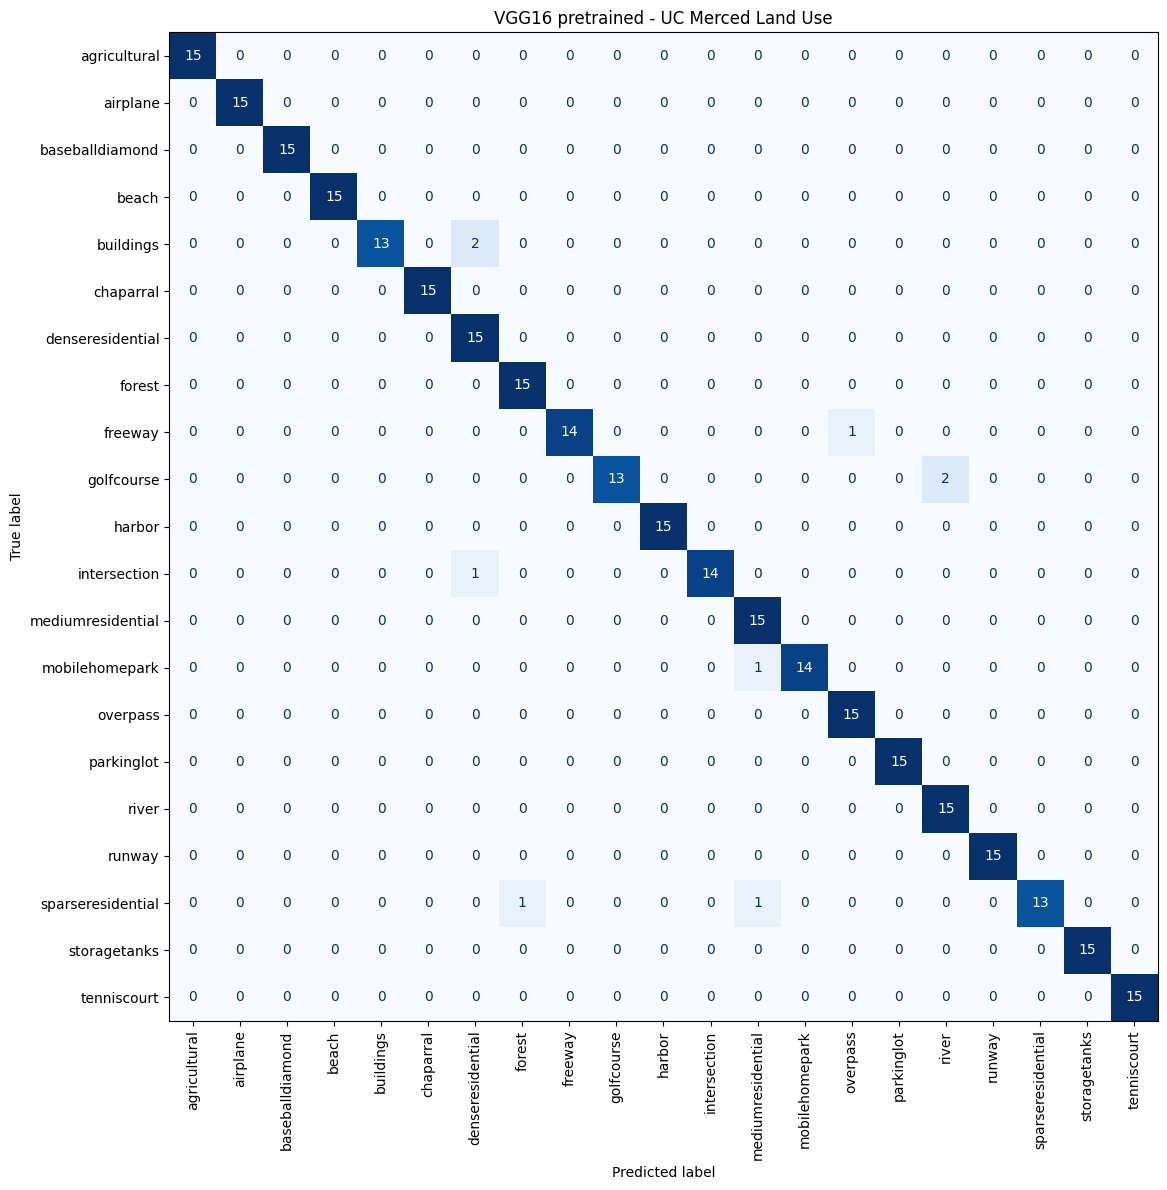

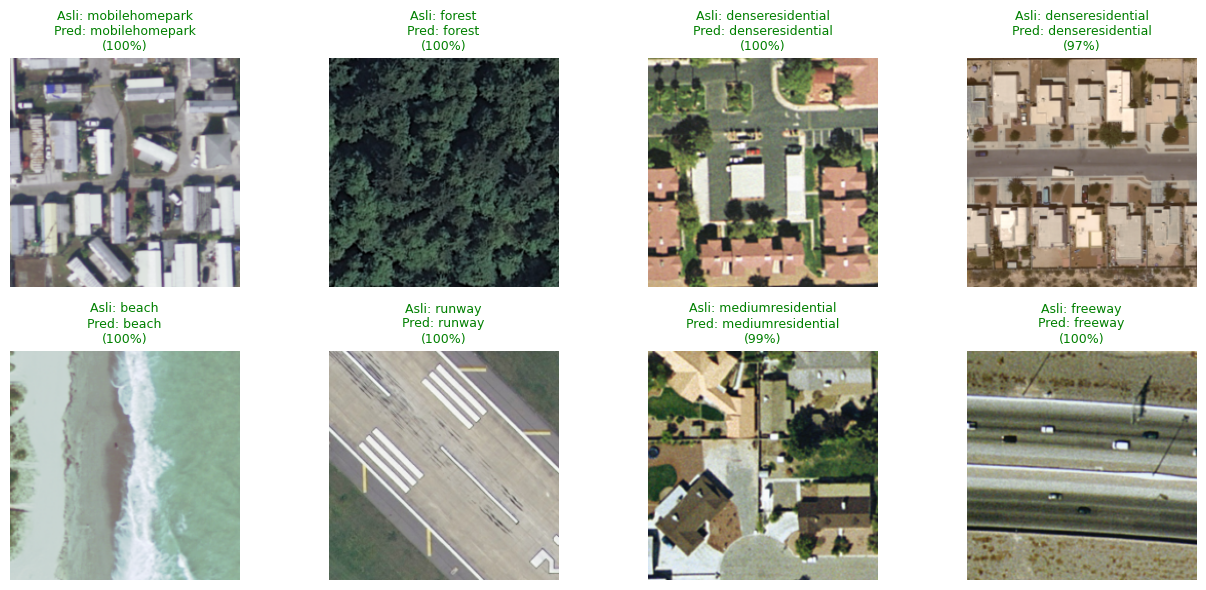

In [ ]:
evaluasi(model_vgg, "VGG16")

## Model 2: MobileNetV2

In [ ]:
tf.keras.utils.set_random_seed(42)

base_mob = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)
base_mob.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))

x = AUGMENTASI()(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_mob(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(len(nama_kelas), activation="softmax")(x)

model_mob = tf.keras.Model(inputs, outputs, name="mobilenetv2_ucmerced")

model_mob.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_mob.summary()


Model: "mobilenetv2_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 21)             │        26,901 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,284,885 (8.72 MB)

 Trainable params: 26,901 (105.08 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history_mob = model_mob.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch tahap 1:", len(history_mob.history["loss"]))


Epoch 1/10
92/92 - 11s - 116ms/step - accuracy: 0.5367 - loss: 1.6290 - val_accuracy: 0.8635 - val_loss: 0.5313
Epoch 2/10
92/92 - 4s - 38ms/step - accuracy: 0.8517 - loss: 0.4971 - val_accuracy: 0.9111 - val_loss: 0.3310
Epoch 3/10
92/92 - 4s - 38ms/step - accuracy: 0.8946 - loss: 0.3436 - val_accuracy: 0.9270 - val_loss: 0.2597
Epoch 4/10
92/92 - 4s - 39ms/step - accuracy: 0.9075 - loss: 0.2758 - val_accuracy: 0.9302 - val_loss: 0.2256
Epoch 5/10
92/92 - 4s - 39ms/step - accuracy: 0.9361 - loss: 0.2201 - val_accuracy: 0.9270 - val_loss: 0.2071
Epoch 6/10
92/92 - 4s - 39ms/step - accuracy: 0.9449 - loss: 0.1889 - val_accuracy: 0.9302 - val_loss: 0.2070
Epoch 7/10
92/92 - 4s - 39ms/step - accuracy: 0.9503 - loss: 0.1734 - val_accuracy: 0.9333 - val_loss: 0.1776
Epoch 8/10
92/92 - 4s - 38ms/step - accuracy: 0.9469 - loss: 0.1655 - val_accuracy: 0.9397 - val_loss: 0.1908
Epoch 9/10
92/92 - 4s - 39ms/step - accuracy: 0.9571 - loss: 0.1453 - val_accuracy: 0.9429 - val_loss: 0.1511
Epoch 10

In [ ]:
base_mob.trainable = True
for layer in base_mob.layers[:100]:
    layer.trainable = False

model_mob.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop_ft = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)

history_mob_ft = model_mob.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop_ft],
    verbose=2
)

print("Epoch tahap 2:", len(history_mob_ft.history["loss"]))


Epoch 1/20
92/92 - 19s - 211ms/step - accuracy: 0.7551 - loss: 0.8294 - val_accuracy: 0.9587 - val_loss: 0.1266
Epoch 2/20
92/92 - 5s - 59ms/step - accuracy: 0.8340 - loss: 0.5490 - val_accuracy: 0.9587 - val_loss: 0.1280
Epoch 3/20
92/92 - 5s - 60ms/step - accuracy: 0.8646 - loss: 0.4538 - val_accuracy: 0.9556 - val_loss: 0.1271
Epoch 4/20
92/92 - 6s - 61ms/step - accuracy: 0.9000 - loss: 0.3714 - val_accuracy: 0.9587 - val_loss: 0.1241
Epoch 5/20
92/92 - 6s - 62ms/step - accuracy: 0.9184 - loss: 0.3121 - val_accuracy: 0.9587 - val_loss: 0.1213
Epoch 6/20
92/92 - 6s - 61ms/step - accuracy: 0.9143 - loss: 0.2970 - val_accuracy: 0.9651 - val_loss: 0.1142
Epoch 7/20
92/92 - 6s - 61ms/step - accuracy: 0.9245 - loss: 0.2642 - val_accuracy: 0.9683 - val_loss: 0.1092
Epoch 8/20
92/92 - 6s - 60ms/step - accuracy: 0.9381 - loss: 0.2322 - val_accuracy: 0.9619 - val_loss: 0.1134
Epoch 9/20
92/92 - 6s - 60ms/step - accuracy: 0.9401 - loss: 0.2175 - val_accuracy: 0.9651 - val_loss: 0.1060
Epoch 10

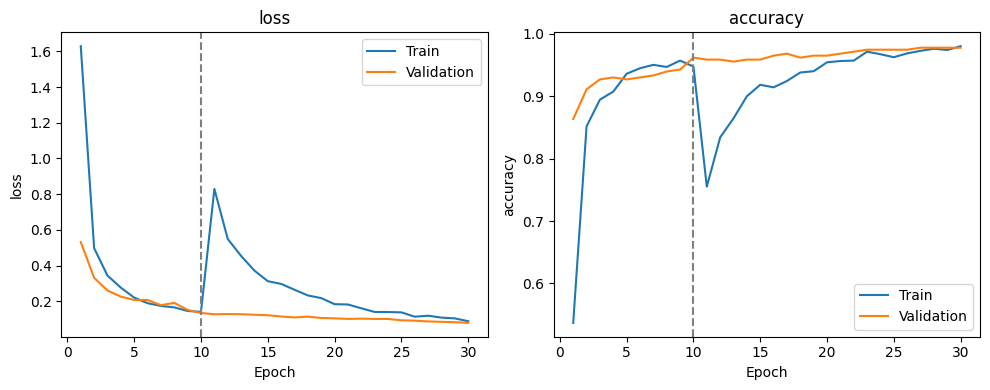

In [ ]:
plot_history(history_mob, history_mob_ft)

Test loss: 0.1261 | Test accuracy: 94.92%
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        15
         airplane       0.94      1.00      0.97        15
  baseballdiamond       0.94      1.00      0.97        15
            beach       1.00      1.00      1.00        15
        buildings       1.00      1.00      1.00        15
        chaparral       1.00      1.00      1.00        15
 denseresidential       0.92      0.80      0.86        15
           forest       0.94      1.00      0.97        15
          freeway       1.00      0.93      0.97        15
       golfcourse       1.00      0.73      0.85        15
           harbor       1.00      1.00      1.00        15
     intersection       1.00      0.93      0.97        15
mediumresidential       0.71      0.80      0.75        15
   mobilehomepark       0.93      0.93      0.93        15
         overpass       0.94      1.00      0.97        15
       parkin

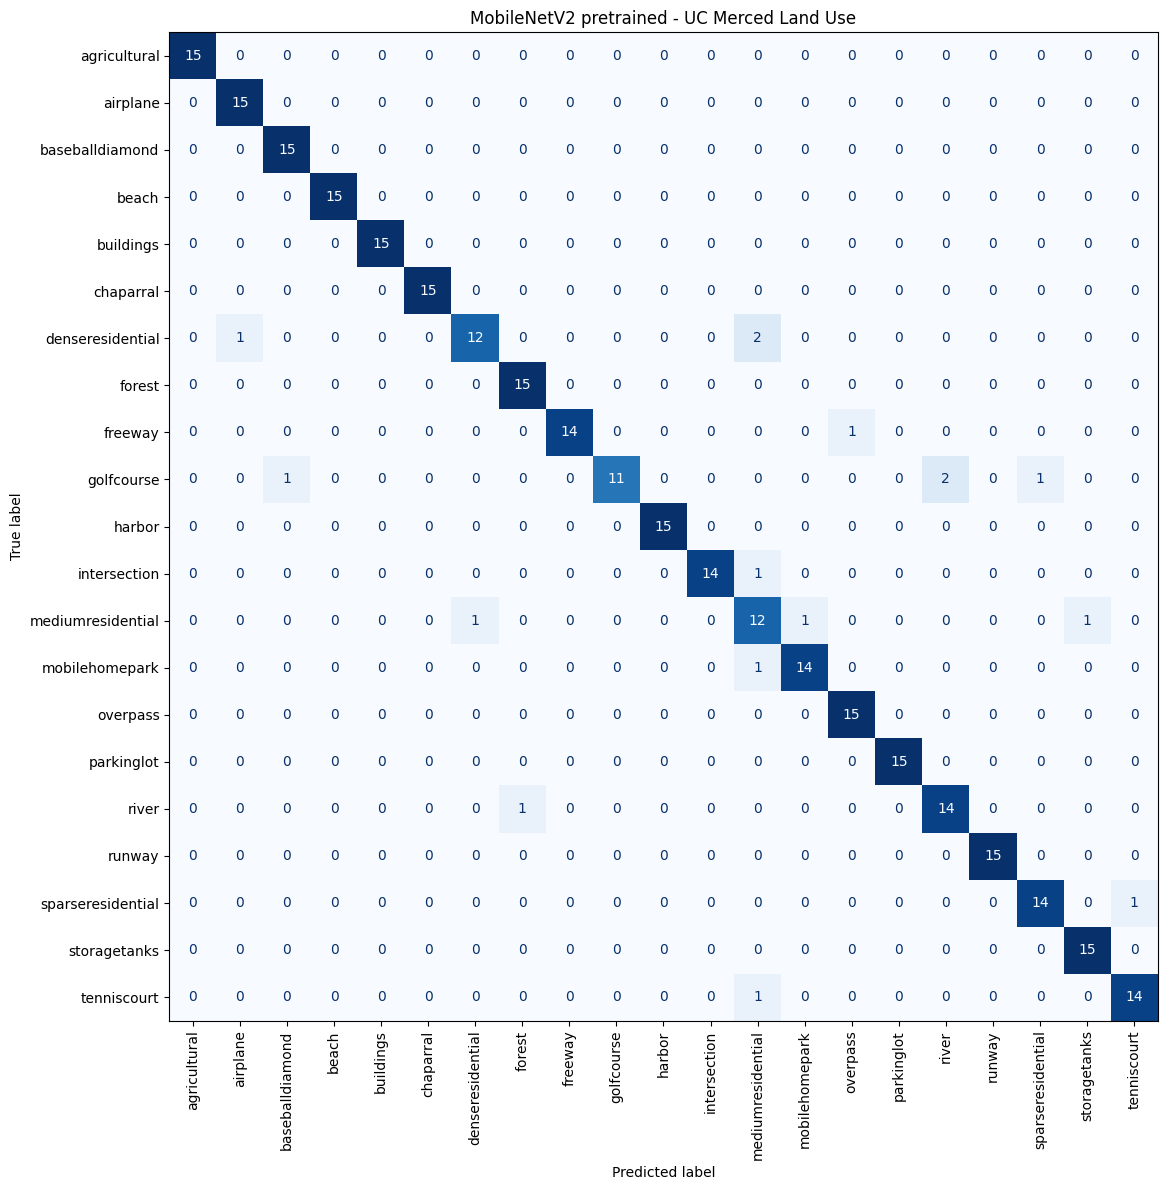

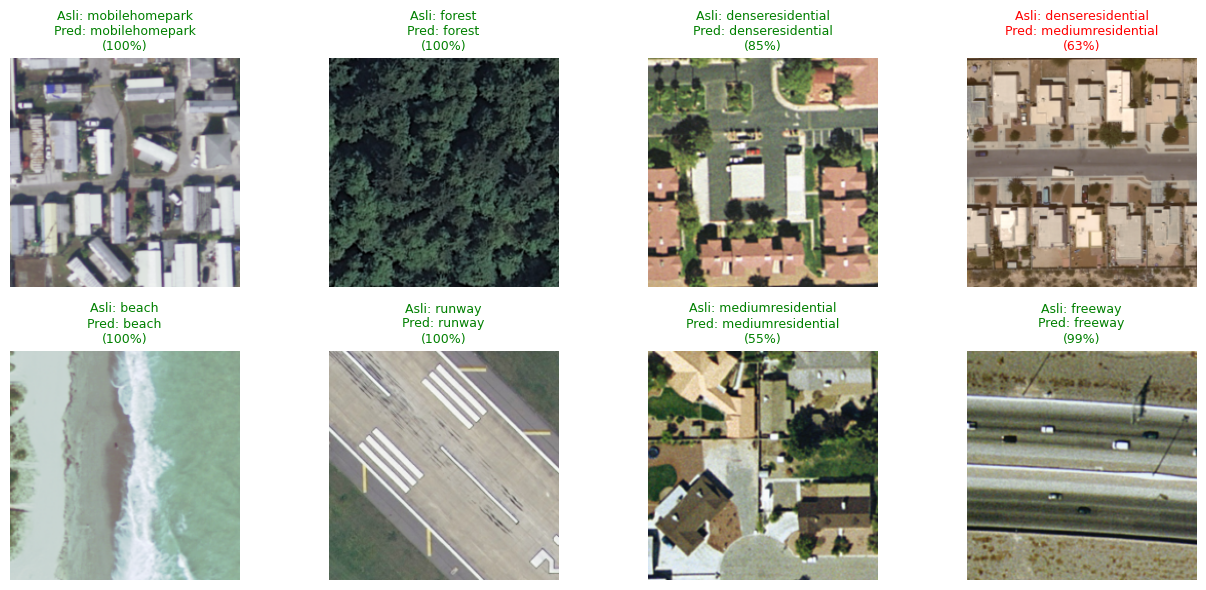

In [ ]:
evaluasi(model_mob, "MobileNetV2")

## Perbandingan

In [ ]:
tabel = pd.DataFrame(hasil).T
tabel["Test accuracy"] = tabel["Test accuracy"].map("{:.2%}".format)
tabel["Test loss"] = tabel["Test loss"].map("{:.4f}".format)
tabel


,Test loss,Test accuracy
VGG16,0.1367,97.14%
MobileNetV2,0.1261,94.92%
